In [163]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from tensorflow import keras
import tensorflow 
from tensorflow.keras.layers import Dense ,Input
from tensorflow.keras import Sequential
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt

In [46]:
data = pd.read_csv('../data/Admission_Predict.csv')
data.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [47]:
data.isnull().sum()

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

In [48]:
data.drop(columns=["Serial No."],inplace=True)

In [49]:
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,0.92
1,324,107,4,4.0,4.5,8.87,1,0.76
2,316,104,3,3.0,3.5,8.00,1,0.72
3,322,110,3,3.5,2.5,8.67,1,0.80
4,314,103,2,2.0,3.0,8.21,0,0.65
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1,0.82
396,325,107,3,3.0,3.5,9.11,1,0.84
397,330,116,4,5.0,4.5,9.45,1,0.91
398,312,103,3,3.5,4.0,8.78,0,0.67


In [50]:
data.duplicated().sum()

np.int64(0)

In [51]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GRE Score          400 non-null    int64  
 1   TOEFL Score        400 non-null    int64  
 2   University Rating  400 non-null    int64  
 3   SOP                400 non-null    float64
 4   LOR                400 non-null    float64
 5   CGPA               400 non-null    float64
 6   Research           400 non-null    int64  
 7   Chance of Admit    400 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.1 KB


In [52]:
X = data.iloc[:,0:-1].values

In [53]:
X

array([[337.  , 118.  ,   4.  , ...,   4.5 ,   9.65,   1.  ],
       [324.  , 107.  ,   4.  , ...,   4.5 ,   8.87,   1.  ],
       [316.  , 104.  ,   3.  , ...,   3.5 ,   8.  ,   1.  ],
       ...,
       [330.  , 116.  ,   4.  , ...,   4.5 ,   9.45,   1.  ],
       [312.  , 103.  ,   3.  , ...,   4.  ,   8.78,   0.  ],
       [333.  , 117.  ,   4.  , ...,   4.  ,   9.66,   1.  ]],
      shape=(400, 7))

In [54]:
y = data.iloc[:,-1].values

In [55]:
y

array([0.92, 0.76, 0.72, 0.8 , 0.65, 0.9 , 0.75, 0.68, 0.5 , 0.45, 0.52,
       0.84, 0.78, 0.62, 0.61, 0.54, 0.66, 0.65, 0.63, 0.62, 0.64, 0.7 ,
       0.94, 0.95, 0.97, 0.94, 0.76, 0.44, 0.46, 0.54, 0.65, 0.74, 0.91,
       0.9 , 0.94, 0.88, 0.64, 0.58, 0.52, 0.48, 0.46, 0.49, 0.53, 0.87,
       0.91, 0.88, 0.86, 0.89, 0.82, 0.78, 0.76, 0.56, 0.78, 0.72, 0.7 ,
       0.64, 0.64, 0.46, 0.36, 0.42, 0.48, 0.47, 0.54, 0.56, 0.52, 0.55,
       0.61, 0.57, 0.68, 0.78, 0.94, 0.96, 0.93, 0.84, 0.74, 0.72, 0.74,
       0.64, 0.44, 0.46, 0.5 , 0.96, 0.92, 0.92, 0.94, 0.76, 0.72, 0.66,
       0.64, 0.74, 0.64, 0.38, 0.34, 0.44, 0.36, 0.42, 0.48, 0.86, 0.9 ,
       0.79, 0.71, 0.64, 0.62, 0.57, 0.74, 0.69, 0.87, 0.91, 0.93, 0.68,
       0.61, 0.69, 0.62, 0.72, 0.59, 0.66, 0.56, 0.45, 0.47, 0.71, 0.94,
       0.94, 0.57, 0.61, 0.57, 0.64, 0.85, 0.78, 0.84, 0.92, 0.96, 0.77,
       0.71, 0.79, 0.89, 0.82, 0.76, 0.71, 0.8 , 0.78, 0.84, 0.9 , 0.92,
       0.97, 0.8 , 0.81, 0.75, 0.83, 0.96, 0.79, 0.

In [56]:
scaler = StandardScaler()

In [57]:
X = scaler.fit_transform(X)
X

array([[ 1.76210664,  1.74697064,  0.79882862, ...,  1.16732114,
         1.76481828,  0.90911166],
       [ 0.62765641, -0.06763531,  0.79882862, ...,  1.16732114,
         0.45515126,  0.90911166],
       [-0.07046681, -0.56252785, -0.07660001, ...,  0.05293342,
        -1.00563118,  0.90911166],
       ...,
       [ 1.15124883,  1.41704229,  0.79882862, ...,  1.16732114,
         1.42900622,  0.90911166],
       [-0.41952842, -0.72749202, -0.07660001, ...,  0.61012728,
         0.30403584, -1.09997489],
       [ 1.41304503,  1.58200646,  0.79882862, ...,  0.61012728,
         1.78160888,  0.90911166]], shape=(400, 7))

In [58]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1,random_state=0)

In [59]:
model = Sequential()

In [60]:
X_train.shape

(360, 7)

In [61]:
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(3, activation='relu'))
model.add(Dense(1, activation='linear'))

In [62]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28 (112.00 B)

 Trainable params: 28 (112.00 B)

 Non-trainable params: 0 (0.00 B)

In [63]:
model.compile(optimizer='Adam',loss='mean_squared_error')

In [65]:
model.fit(X_train,y_train,epochs=10,verbose=1,batch_size=10)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 628us/step - loss: 0.8313
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 411us/step - loss: 0.6367
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 442us/step - loss: 0.4930
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - loss: 0.3920
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 447us/step - loss: 0.3149
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step - loss: 0.2594
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 404us/step - loss: 0.2187
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step - loss: 0.1841
Epoch 9/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step - loss: 0.1575
Epoch 10/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 407us/step - loss: 0.1363


In [66]:
y_pred = model.predict(X_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [68]:
r2_score(y_test,y_pred)

-10.950804165105962

## Model Evaluation and Improvements
- Increase no of nodes in the hiddlen layer
- Increase no of epochs
- Add more layers

In [133]:
model2 = Sequential()


In [134]:
model2.add(Input(shape=(X_train.shape[1],)))
model2.add(Dense(7, activation='relu'))
model2.add(Dense(3, activation='relu'))
model2.add(Dense(2, activation='relu'))
model2.add(Dense(1, activation='linear'))

In [135]:
model2.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_35 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91 (364.00 B)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

In [136]:
model2.compile(optimizer='Adam',loss='mean_squared_error')

In [137]:
model2.fit(X_train,y_train,epochs=100,verbose=1,batch_size=10)

Epoch 1/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 581us/step - loss: 0.3187 
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - loss: 0.2227
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 507us/step - loss: 0.1766
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 437us/step - loss: 0.1423
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 431us/step - loss: 0.1158
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 443us/step - loss: 0.0951
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step - loss: 0.0788
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 436us/step - loss: 0.0651
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 425us/step - loss: 0.0543
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 405us/step - loss: 0.0449
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 433us/step - loss: 0.0372
Epoch 12/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 430us/step - loss: 0.0314
Epoch 13/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 417us/step - loss: 0.0268
Epoch 14/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 421us/step - loss: 0.0232
Epoch 15/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s

In [138]:
y_pred2 = model2.predict(X_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [139]:
r2_score(y_test,y_pred2)

0.7716523544772926

## Validation

In [154]:
model3 = Sequential()

In [155]:
model3.add(Input(shape=(X_train.shape[1],)))
model3.add(Dense(7, activation='relu'))
model3.add(Dense(3, activation='relu'))
model3.add(Dense(2, activation='relu'))
model3.add(Dense(1, activation='linear'))

In [156]:
model3.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_47 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 3)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 2)              │             8 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91 (364.00 B)

 Trainable params: 91 (364.00 B)

 Non-trainable params: 0 (0.00 B)

In [157]:
model3.compile(optimizer='Adam',loss='mean_squared_error')

In [158]:
history = model3.fit(X_train,y_train,epochs=100,verbose=1,batch_size=10,validation_split=0.2)

Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.6844 - val_loss: 1.2763
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.8081 - val_loss: 0.6666
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.4692 - val_loss: 0.4257
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 898us/step - loss: 0.3313 - val_loss: 0.3383
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - loss: 0.2740 - val_loss: 0.2900
Epoch 6/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - loss: 0.2425 - val_loss: 0.2613
Epoch 7/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 881us/step - loss: 0.2216 - val_loss: 0.2423
Epoch 8/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 906us/step - loss: 0.2057 - val_loss: 0.2277
Epoch 9/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - loss: 0.1919 - val_loss: 0.2147
Epoch 10/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step - loss: 0.1791 - val_loss: 0.2038
Epoch 11/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 888us/step - loss: 0.1668 - val_loss: 0.1932
Epoch 12/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 841u

In [159]:
y_pred3 = model3.predict(X_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


In [160]:
r2_score(y_test,y_pred3)

0.6826783269164638

In [162]:
history.history

{'loss': [1.6844279766082764,
  0.8081342577934265,
  0.4691905379295349,
  0.3313038945198059,
  0.27403002977371216,
  0.24245095252990723,
  0.22163233160972595,
  0.2057008594274521,
  0.19185204803943634,
  0.17906735837459564,
  0.16678835451602936,
  0.15514153242111206,
  0.14383572340011597,
  0.13297581672668457,
  0.12217455357313156,
  0.1122962236404419,
  0.10354483127593994,
  0.09510733187198639,
  0.08749047666788101,
  0.08038584887981415,
  0.0743974894285202,
  0.06900986284017563,
  0.06433924287557602,
  0.060298580676317215,
  0.056442856788635254,
  0.05315186455845833,
  0.05015178024768829,
  0.04735726863145828,
  0.04496872052550316,
  0.04267169535160065,
  0.040683552622795105,
  0.038631416857242584,
  0.03692097216844559,
  0.035070206969976425,
  0.0335221141576767,
  0.03213861957192421,
  0.0307909045368433,
  0.029582420364022255,
  0.028415245935320854,
  0.02733602002263069,
  0.02640785090625286,
  0.02552897110581398,
  0.02462735027074814,
  0.0

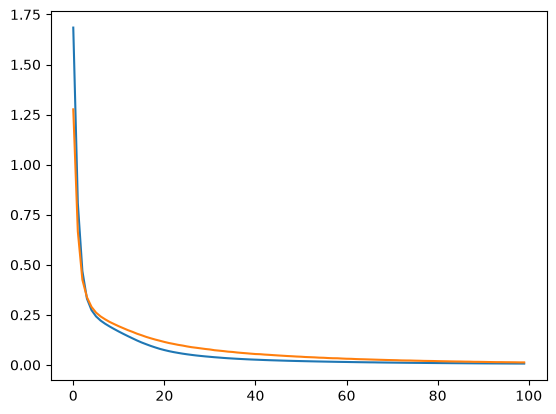

In [166]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])